In [1]:

# Milestone 6: Attrition Model Development
# Step 1: Import libraries and load preprocessed data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path

# Scikit-learn models and evaluation metrics
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

# Configure visualization
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# Locate project root
PROJECT_ROOT = Path.cwd().parent

# Define directories
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"

# Load preprocessed datasets
X_train = np.load(PROCESSED_DIR / "X_train_processed.npy")
X_test = np.load(PROCESSED_DIR / "X_test_processed.npy")

y_train = np.load(PROCESSED_DIR / "y_train.npy")
y_test = np.load(PROCESSED_DIR / "y_test.npy")

# Load fitted preprocessing pipeline
preprocessor = joblib.load(
    MODEL_DIR / "attrition_preprocessor.joblib"
)

# Display dataset information
print("Preprocessed Data Loaded Successfully!")

print("\nTraining Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Attrition Distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting Attrition Distribution:")
print(pd.Series(y_test).value_counts().sort_index())


Preprocessed Data Loaded Successfully!

Training Features: (1176, 51)
Testing Features: (294, 51)

Training Target: (1176,)
Testing Target: (294,)

Training Attrition Distribution:
0    986
1    190
Name: count, dtype: int64

Testing Attrition Distribution:
0    247
1     47
Name: count, dtype: int64


In [2]:

# Step 2: Logistic Regression Model

# Initialize Logistic Regression
logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

# Train model
print("Training Logistic Regression Model...")

logistic_model.fit(X_train, y_train)

print("Logistic Regression Training Completed!")

# Generate predictions
y_pred_lr = logistic_model.predict(X_test)

# Generate prediction probabilities
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

print("\nPredictions Generated Successfully!")

# Calculate evaluation metrics
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr, zero_division=0)
lr_recall = recall_score(y_test, y_pred_lr, zero_division=0)
lr_f1 = f1_score(y_test, y_pred_lr, zero_division=0)
lr_roc_auc = roc_auc_score(y_test, y_prob_lr)

# Display results
print("\n========== LOGISTIC REGRESSION RESULTS ==========")

print(f"Accuracy  : {lr_accuracy:.4f}")
print(f"Precision : {lr_precision:.4f}")
print(f"Recall    : {lr_recall:.4f}")
print(f"F1-Score  : {lr_f1:.4f}")
print(f"ROC-AUC   : {lr_roc_auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=["No Attrition", "Attrition"],
        zero_division=0
    )
)


Training Logistic Regression Model...
Logistic Regression Training Completed!

Predictions Generated Successfully!

========== LOGISTIC REGRESSION RESULTS ==========
Accuracy  : 0.7517
Precision : 0.3488
Recall    : 0.6383
F1-Score  : 0.4511
ROC-AUC   : 0.8032

Classification Report:
              precision    recall  f1-score   support

No Attrition       0.92      0.77      0.84       247
   Attrition       0.35      0.64      0.45        47

    accuracy                           0.75       294
   macro avg       0.63      0.71      0.65       294
weighted avg       0.83      0.75      0.78       294



Logistic Regression Confusion Matrix:
[[191  56]
 [ 17  30]]


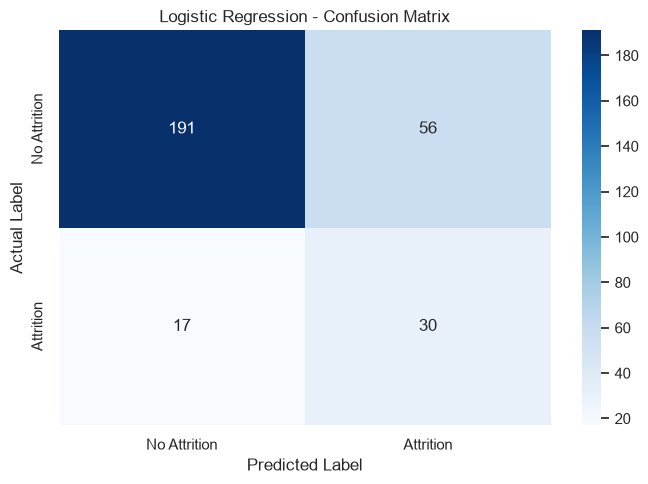

In [3]:

# Step 3: Logistic Regression Confusion Matrix

# Calculate confusion matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)

print("Logistic Regression Confusion Matrix:")
print(cm_lr)

# Plot confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Attrition", "Attrition"],
    yticklabels=["No Attrition", "Attrition"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()

# Save figure
plt.savefig(
    FIGURE_DIR / "11_logistic_regression_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [4]:

# Step 4: Save Logistic Regression Model

import joblib

MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save trained model
lr_model_path = MODEL_DIR / "logistic_regression_model.joblib"

joblib.dump(
    logistic_model,
    lr_model_path
)

print("Logistic Regression model saved successfully!")
print("Saved location:", lr_model_path)

# Verify saved model
loaded_lr_model = joblib.load(lr_model_path)

print("\nModel loaded successfully!")
print("Model type:", type(loaded_lr_model).__name__)


Logistic Regression model saved successfully!
Saved location: c:\Projects\AI_HR_Prediction\models\logistic_regression_model.joblib

Model loaded successfully!
Model type: LogisticRegression


In [5]:

# Step 5: Decision Tree Classifier

# Initialize Decision Tree
decision_tree_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)

# Train model
print("Training Decision Tree Model...")

decision_tree_model.fit(X_train, y_train)

print("Decision Tree Training Completed!")

# Generate predictions
y_pred_dt = decision_tree_model.predict(X_test)

# Generate prediction probabilities
y_prob_dt = decision_tree_model.predict_proba(X_test)[:, 1]

print("\nPredictions Generated Successfully!")

# Calculate evaluation metrics
dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt, zero_division=0)
dt_recall = recall_score(y_test, y_pred_dt, zero_division=0)
dt_f1 = f1_score(y_test, y_pred_dt, zero_division=0)
dt_roc_auc = roc_auc_score(y_test, y_prob_dt)

# Display results
print("\n========== DECISION TREE RESULTS ==========")

print(f"Accuracy  : {dt_accuracy:.4f}")
print(f"Precision : {dt_precision:.4f}")
print(f"Recall    : {dt_recall:.4f}")
print(f"F1-Score  : {dt_f1:.4f}")
print(f"ROC-AUC   : {dt_roc_auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_dt,
        target_names=["No Attrition", "Attrition"],
        zero_division=0
    )
)


Training Decision Tree Model...
Decision Tree Training Completed!

Predictions Generated Successfully!

========== DECISION TREE RESULTS ==========
Accuracy  : 0.7585
Precision : 0.3286
Recall    : 0.4894
F1-Score  : 0.3932
ROC-AUC   : 0.6320

Classification Report:
              precision    recall  f1-score   support

No Attrition       0.89      0.81      0.85       247
   Attrition       0.33      0.49      0.39        47

    accuracy                           0.76       294
   macro avg       0.61      0.65      0.62       294
weighted avg       0.80      0.76      0.78       294



Decision Tree Confusion Matrix:
[[200  47]
 [ 24  23]]


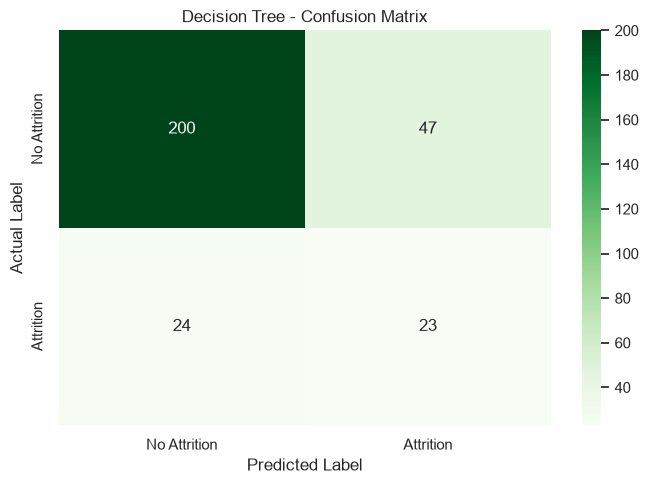

In [6]:

# Step 6: Decision Tree Confusion Matrix

# Calculate confusion matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)

print("Decision Tree Confusion Matrix:")
print(cm_dt)

# Plot confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Attrition", "Attrition"],
    yticklabels=["No Attrition", "Attrition"]
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()

# Save figure
plt.savefig(
    FIGURE_DIR / "12_decision_tree_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [7]:

# Step 7: Save Decision Tree Model

dt_model_path = MODEL_DIR / "decision_tree_model.joblib"

joblib.dump(
    decision_tree_model,
    dt_model_path
)

print("Decision Tree model saved successfully!")
print("Saved location:", dt_model_path)

# Verify saved model
loaded_dt_model = joblib.load(dt_model_path)

print("\nModel loaded successfully!")
print("Model type:", type(loaded_dt_model).__name__)


Decision Tree model saved successfully!
Saved location: c:\Projects\AI_HR_Prediction\models\decision_tree_model.joblib

Model loaded successfully!
Model type: DecisionTreeClassifier


In [9]:

# Step 8: Random Forest Classifier

# Initialize Random Forest
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=4,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train model
print("Training Random Forest Model...")

random_forest_model.fit(X_train, y_train)

print("Random Forest Training Completed!")

# Generate predictions
y_pred_rf = random_forest_model.predict(X_test)

# Generate prediction probabilities
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

print("\nPredictions Generated Successfully!")

# Calculate evaluation metrics
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, zero_division=0)
rf_recall = recall_score(y_test, y_pred_rf, zero_division=0)
rf_f1 = f1_score(y_test, y_pred_rf, zero_division=0)
rf_roc_auc = roc_auc_score(y_test, y_prob_rf)

# Display results
print("\n========== RANDOM FOREST RESULTS ==========")

print(f"Accuracy  : {rf_accuracy:.4f}")
print(f"Precision : {rf_precision:.4f}")
print(f"Recall    : {rf_recall:.4f}")
print(f"F1-Score  : {rf_f1:.4f}")
print(f"ROC-AUC   : {rf_roc_auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=["No Attrition", "Attrition"],
        zero_division=0
    )
)


Training Random Forest Model...
Random Forest Training Completed!

Predictions Generated Successfully!

========== RANDOM FOREST RESULTS ==========
Accuracy  : 0.8231
Precision : 0.4576
Recall    : 0.5745
F1-Score  : 0.5094
ROC-AUC   : 0.7879

Classification Report:
              precision    recall  f1-score   support

No Attrition       0.91      0.87      0.89       247
   Attrition       0.46      0.57      0.51        47

    accuracy                           0.82       294
   macro avg       0.69      0.72      0.70       294
weighted avg       0.84      0.82      0.83       294



Random Forest Confusion Matrix:
[[215  32]
 [ 20  27]]


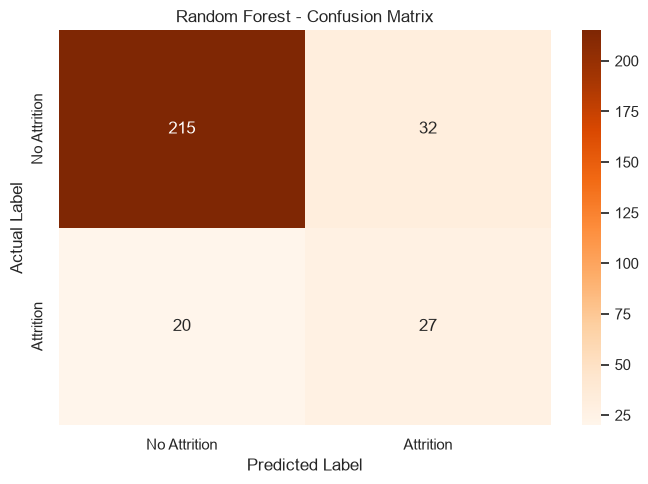

In [10]:

# Step 9: Random Forest Confusion Matrix

# Calculate confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

print("Random Forest Confusion Matrix:")
print(cm_rf)

# Plot confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["No Attrition", "Attrition"],
    yticklabels=["No Attrition", "Attrition"]
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()

# Save figure
plt.savefig(
    FIGURE_DIR / "13_random_forest_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [11]:

# Step 10: Save Random Forest Model

rf_model_path = MODEL_DIR / "random_forest_model.joblib"

joblib.dump(
    random_forest_model,
    rf_model_path
)

print("Random Forest model saved successfully!")
print("Saved location:", rf_model_path)

# Verify saved model
loaded_rf_model = joblib.load(rf_model_path)

print("\nModel loaded successfully!")
print("Model type:", type(loaded_rf_model).__name__)


Random Forest model saved successfully!
Saved location: c:\Projects\AI_HR_Prediction\models\random_forest_model.joblib

Model loaded successfully!
Model type: RandomForestClassifier


========== MODEL PERFORMANCE COMPARISON ==========


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,75.17,34.88,63.83,45.11,80.32
Decision Tree,75.85,32.86,48.94,39.32,63.20
Random Forest,82.31,45.76,57.45,50.94,78.79


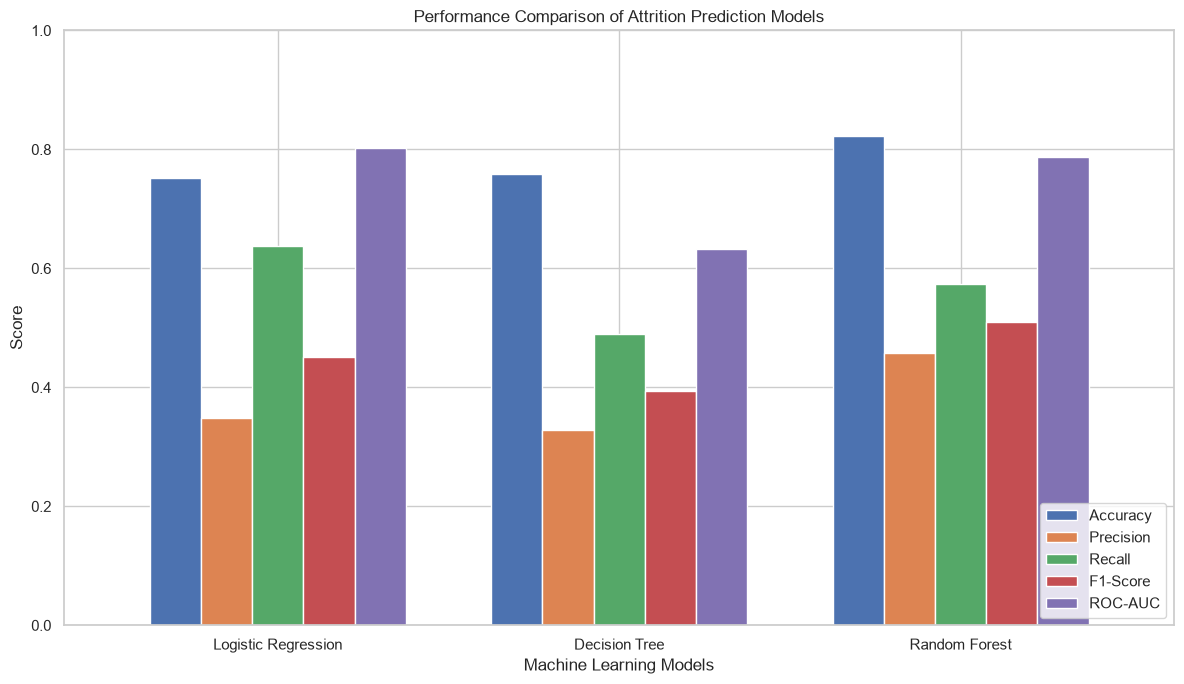


Model comparison completed successfully!


In [12]:

# Step 11: Compare All Three Models

# Create comparison dictionary
model_results = {
    "Logistic Regression": {
        "Accuracy": lr_accuracy,
        "Precision": lr_precision,
        "Recall": lr_recall,
        "F1-Score": lr_f1,
        "ROC-AUC": lr_roc_auc
    },

    "Decision Tree": {
        "Accuracy": dt_accuracy,
        "Precision": dt_precision,
        "Recall": dt_recall,
        "F1-Score": dt_f1,
        "ROC-AUC": dt_roc_auc
    },

    "Random Forest": {
        "Accuracy": rf_accuracy,
        "Precision": rf_precision,
        "Recall": rf_recall,
        "F1-Score": rf_f1,
        "ROC-AUC": rf_roc_auc
    }
}

# Convert to DataFrame
comparison_df = pd.DataFrame(model_results).T

# Display comparison
print("========== MODEL PERFORMANCE COMPARISON ==========")

display(
    (comparison_df * 100).round(2).rename_axis("Model")
)

# Save comparison table
comparison_df.to_csv(
    PROJECT_ROOT / "reports" / "model_comparison.csv"
)

# Plot comparison
comparison_df.plot(
    kind="bar",
    figsize=(12, 7),
    width=0.75
)

plt.title("Performance Comparison of Attrition Prediction Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()

# Save figure
plt.savefig(
    FIGURE_DIR / "14_model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nModel comparison completed successfully!")


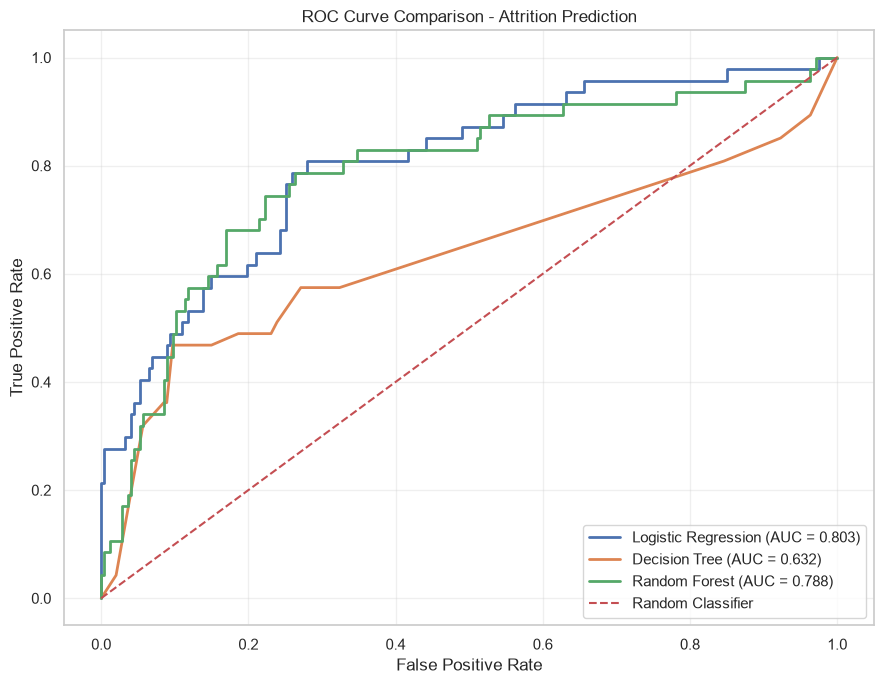

ROC curve comparison completed successfully!


In [13]:

# Step 12: ROC Curve Comparison

# Calculate ROC curves
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

# Plot ROC curves
plt.figure(figsize=(9, 7))

plt.plot(
    fpr_lr,
    tpr_lr,
    label=f"Logistic Regression (AUC = {lr_roc_auc:.3f})",
    linewidth=2
)

plt.plot(
    fpr_dt,
    tpr_dt,
    label=f"Decision Tree (AUC = {dt_roc_auc:.3f})",
    linewidth=2
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {rf_roc_auc:.3f})",
    linewidth=2
)

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve Comparison - Attrition Prediction")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

# Save figure
plt.savefig(
    FIGURE_DIR / "15_roc_curve_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ROC curve comparison completed successfully!")


In [14]:

# Step 13: Save Final Initial Model Evaluation Results

# Create detailed evaluation table
evaluation_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        lr_accuracy,
        dt_accuracy,
        rf_accuracy
    ],
    "Precision": [
        lr_precision,
        dt_precision,
        rf_precision
    ],
    "Recall": [
        lr_recall,
        dt_recall,
        rf_recall
    ],
    "F1_Score": [
        lr_f1,
        dt_f1,
        rf_f1
    ],
    "ROC_AUC": [
        lr_roc_auc,
        dt_roc_auc,
        rf_roc_auc
    ]
})

# Save evaluation results
evaluation_path = PROJECT_ROOT / "reports" / "model_evaluation_results.csv"

evaluation_df.to_csv(
    evaluation_path,
    index=False
)

print("Model evaluation results saved successfully!")

print("\nFinal Initial Evaluation Results:")
display(evaluation_df.round(4))

print("\nSaved location:", evaluation_path)


Model evaluation results saved successfully!

Final Initial Evaluation Results:


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Logistic Regression,0.7517,0.3488,0.6383,0.4511,0.8032
1,Decision Tree,0.7585,0.3286,0.4894,0.3932,0.6320
2,Random Forest,0.8231,0.4576,0.5745,0.5094,0.7879



Saved location: c:\Projects\AI_HR_Prediction\reports\model_evaluation_results.csv


In [17]:
# Import all libraries required for Step 14

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [18]:

# Step 14: Create a Leakage-Safe Validation Split

from sklearn.model_selection import train_test_split

# Reload original dataset
raw_df = pd.read_csv(
    PROJECT_ROOT / "data" / "raw" /
    "WA_Fn-UseC_-HR-Employee-Attrition.csv"
)

# Separate features and target
columns_to_drop = [
    "Attrition",
    "EmployeeNumber",
    "EmployeeCount",
    "Over18",
    "StandardHours"
]

X_raw = raw_df.drop(columns=columns_to_drop)

y_raw = raw_df["Attrition"].map({
    "No": 0,
    "Yes": 1
})

# Recreate original 80:20 development/test split
X_development, X_final_test, y_development, y_final_test = (
    train_test_split(
        X_raw,
        y_raw,
        test_size=0.20,
        random_state=42,
        stratify=y_raw
    )
)

# Split development data into model-fitting and validation sets
X_fit, X_validation, y_fit, y_validation = train_test_split(
    X_development,
    y_development,
    test_size=0.20,
    random_state=42,
    stratify=y_development
)

# Identify feature types
numerical_features = X_fit.select_dtypes(
    include="number"
).columns.tolist()

categorical_features = X_fit.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

# Create fresh preprocessing pipelines
numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

validation_preprocessor = ColumnTransformer([
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

# Fit ONLY on model-fitting data
X_fit_processed = validation_preprocessor.fit_transform(X_fit)

# Transform validation data without fitting
X_validation_processed = validation_preprocessor.transform(
    X_validation
)

print("Leakage-Safe Validation Split Created!")

print("\nModel-Fitting Data:", X_fit_processed.shape)
print("Validation Data:", X_validation_processed.shape)
print("Final Test Data:", X_final_test.shape)

print("\nModel-Fitting Target Distribution:")
print(y_fit.value_counts())

print("\nValidation Target Distribution:")
print(y_validation.value_counts())

print("\nFinal Test Target Distribution:")
print(y_final_test.value_counts())

print("\nPreprocessing fitted only on model-fitting data.")


Leakage-Safe Validation Split Created!

Model-Fitting Data: (940, 51)
Validation Data: (236, 51)
Final Test Data: (294, 30)

Model-Fitting Target Distribution:
Attrition
0    788
1    152
Name: count, dtype: int64

Validation Target Distribution:
Attrition
0    198
1     38
Name: count, dtype: int64

Final Test Target Distribution:
Attrition
0    247
1     47
Name: count, dtype: int64

Preprocessing fitted only on model-fitting data.


In [19]:

# Step 15: Random Forest Hyperparameter Tuning

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier

# Initialize Random Forest
rf_tuning_model = RandomForestClassifier(
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Define hyperparameter grid
rf_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [5, 10, 20],
    "min_samples_leaf": [2, 4, 6]
}

# Stratified 5-fold cross-validation
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Initialize GridSearchCV
rf_grid_search = GridSearchCV(
    estimator=rf_tuning_model,
    param_grid=rf_param_grid,
    scoring="f1",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1
)

# Perform hyperparameter tuning
print("Starting Random Forest Hyperparameter Tuning...")

rf_grid_search.fit(
    X_fit_processed,
    y_fit
)

print("\nRandom Forest Hyperparameter Tuning Completed!")

# Display best parameters
print("\nBest Parameters:")
print(rf_grid_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(round(rf_grid_search.best_score_, 4))

# Store best model
best_rf_model = rf_grid_search.best_estimator_


Starting Random Forest Hyperparameter Tuning...
Fitting 5 folds for each of 108 candidates, totalling 540 fits

Random Forest Hyperparameter Tuning Completed!

Best Parameters:
{'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 100}

Best Cross-Validation F1-Score:
0.5123


In [20]:

# Step 16: Evaluate Tuned Random Forest on Validation Data

# Generate validation predictions
y_validation_pred_rf = best_rf_model.predict(
    X_validation_processed
)

# Generate probabilities
y_validation_prob_rf = best_rf_model.predict_proba(
    X_validation_processed
)[:, 1]

# Calculate evaluation metrics
rf_val_accuracy = accuracy_score(
    y_validation,
    y_validation_pred_rf
)

rf_val_precision = precision_score(
    y_validation,
    y_validation_pred_rf,
    zero_division=0
)

rf_val_recall = recall_score(
    y_validation,
    y_validation_pred_rf,
    zero_division=0
)

rf_val_f1 = f1_score(
    y_validation,
    y_validation_pred_rf,
    zero_division=0
)

rf_val_roc_auc = roc_auc_score(
    y_validation,
    y_validation_prob_rf
)

# Display results
print("========== TUNED RANDOM FOREST VALIDATION RESULTS ==========")

print(f"Accuracy  : {rf_val_accuracy:.4f}")
print(f"Precision : {rf_val_precision:.4f}")
print(f"Recall    : {rf_val_recall:.4f}")
print(f"F1-Score  : {rf_val_f1:.4f}")
print(f"ROC-AUC   : {rf_val_roc_auc:.4f}")

print("\nValidation Classification Report:")

print(
    classification_report(
        y_validation,
        y_validation_pred_rf,
        target_names=["No Attrition", "Attrition"],
        zero_division=0
    )
)

# Confusion matrix
cm_rf_validation = confusion_matrix(
    y_validation,
    y_validation_pred_rf
)

print("\nValidation Confusion Matrix:")
print(cm_rf_validation)


========== TUNED RANDOM FOREST VALIDATION RESULTS ==========
Accuracy  : 0.8559
Precision : 0.5526
Recall    : 0.5526
F1-Score  : 0.5526
ROC-AUC   : 0.7796

Validation Classification Report:
              precision    recall  f1-score   support

No Attrition       0.91      0.91      0.91       198
   Attrition       0.55      0.55      0.55        38

    accuracy                           0.86       236
   macro avg       0.73      0.73      0.73       236
weighted avg       0.86      0.86      0.86       236


Validation Confusion Matrix:
[[181  17]
 [ 17  21]]


In [21]:

# Step 17: Logistic Regression Hyperparameter Tuning

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Initialize Logistic Regression
lr_tuning_model = LogisticRegression(
    class_weight="balanced",
    max_iter=3000,
    random_state=42
)

# Define hyperparameter grid
lr_param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "solver": ["lbfgs", "liblinear"],
    "penalty": ["l2"]
}

# Stratified 5-fold cross-validation
lr_cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Initialize GridSearchCV
lr_grid_search = GridSearchCV(
    estimator=lr_tuning_model,
    param_grid=lr_param_grid,
    scoring="f1",
    cv=lr_cv_strategy,
    n_jobs=-1,
    verbose=1
)

# Perform tuning
print("Starting Logistic Regression Hyperparameter Tuning...")

lr_grid_search.fit(
    X_fit_processed,
    y_fit
)

print("\nLogistic Regression Hyperparameter Tuning Completed!")

# Display best parameters
print("\nBest Parameters:")
print(lr_grid_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(round(lr_grid_search.best_score_, 4))

# Store best model
best_lr_model = lr_grid_search.best_estimator_


Starting Logistic Regression Hyperparameter Tuning...
Fitting 5 folds for each of 10 candidates, totalling 50 fits

Logistic Regression Hyperparameter Tuning Completed!

Best Parameters:
{'C': 1, 'penalty': 'l2', 'solver': 'lbfgs'}

Best Cross-Validation F1-Score:
0.5106


c:\Projects\AI_HR_Prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [22]:

# Step 18: Tuned Logistic Regression Validation Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Generate predictions
y_validation_pred_lr = best_lr_model.predict(
    X_validation_processed
)

y_validation_prob_lr = best_lr_model.predict_proba(
    X_validation_processed
)[:, 1]

# Calculate evaluation metrics
lr_val_accuracy = accuracy_score(
    y_validation, y_validation_pred_lr
)

lr_val_precision = precision_score(
    y_validation, y_validation_pred_lr, zero_division=0
)

lr_val_recall = recall_score(
    y_validation, y_validation_pred_lr, zero_division=0
)

lr_val_f1 = f1_score(
    y_validation, y_validation_pred_lr, zero_division=0
)

lr_val_roc_auc = roc_auc_score(
    y_validation, y_validation_prob_lr
)

# Display results
print("========== TUNED LOGISTIC REGRESSION VALIDATION RESULTS ==========")

print(f"Accuracy  : {lr_val_accuracy:.4f}")
print(f"Precision : {lr_val_precision:.4f}")
print(f"Recall    : {lr_val_recall:.4f}")
print(f"F1-Score  : {lr_val_f1:.4f}")
print(f"ROC-AUC   : {lr_val_roc_auc:.4f}")

# Classification report
print("\nValidation Classification Report:")

print(
    classification_report(
        y_validation,
        y_validation_pred_lr,
        target_names=["No Attrition", "Attrition"],
        zero_division=0
    )
)

# Confusion matrix
cm_lr_validation = confusion_matrix(
    y_validation,
    y_validation_pred_lr
)

print("\nValidation Confusion Matrix:")
print(cm_lr_validation)


========== TUNED LOGISTIC REGRESSION VALIDATION RESULTS ==========
Accuracy  : 0.7415
Precision : 0.3580
Recall    : 0.7632
F1-Score  : 0.4874
ROC-AUC   : 0.8242

Validation Classification Report:
              precision    recall  f1-score   support

No Attrition       0.94      0.74      0.83       198
   Attrition       0.36      0.76      0.49        38

    accuracy                           0.74       236
   macro avg       0.65      0.75      0.66       236
weighted avg       0.85      0.74      0.77       236


Validation Confusion Matrix:
[[146  52]
 [  9  29]]


In [23]:

# Step 19: Classification Threshold Analysis

import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds = [0.20, 0.25, 0.30, 0.35, 0.40,
              0.45, 0.50, 0.55, 0.60]

results = []

models_probabilities = {
    "Random Forest": y_validation_prob_rf,
    "Logistic Regression": y_validation_prob_lr
}

for model_name, probabilities in models_probabilities.items():

    for threshold in thresholds:

        predictions = (probabilities >= threshold).astype(int)

        precision = precision_score(
            y_validation,
            predictions,
            zero_division=0
        )

        recall = recall_score(
            y_validation,
            predictions,
            zero_division=0
        )

        f1 = f1_score(
            y_validation,
            predictions,
            zero_division=0
        )

        results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision,
            "Recall": recall,
            "F1-Score": f1
        })

threshold_results = pd.DataFrame(results)

print("========== CLASSIFICATION THRESHOLD ANALYSIS ==========")

print(
    threshold_results.round(4).to_string(index=False)
)


========== CLASSIFICATION THRESHOLD ANALYSIS ==========
              Model  Threshold  Precision  Recall  F1-Score
      Random Forest       0.20     0.1882  0.9211    0.3125
      Random Forest       0.25     0.2065  0.8421    0.3316
      Random Forest       0.30     0.2583  0.8158    0.3924
      Random Forest       0.35     0.3086  0.6579    0.4202
      Random Forest       0.40     0.4167  0.6579    0.5102
      Random Forest       0.45     0.4681  0.5789    0.5176
      Random Forest       0.50     0.5526  0.5526    0.5526
      Random Forest       0.55     0.5938  0.5000    0.5429
      Random Forest       0.60     0.6154  0.4211    0.5000
Logistic Regression       0.20     0.2446  0.8947    0.3842
Logistic Regression       0.25     0.2640  0.8684    0.4049
Logistic Regression       0.30     0.2832  0.8421    0.4238
Logistic Regression       0.35     0.2830  0.7895    0.4167
Logistic Regression       0.40     0.3030  0.7895    0.4380
Logistic Regression       0.45     0.3295  0

In [24]:

# Step 20: Compare Selected Operating Points

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)
import pandas as pd

selected_models = {
    "Random Forest (0.50)": {
        "probabilities": y_validation_prob_rf,
        "threshold": 0.50
    },
    "Logistic Regression (0.60)": {
        "probabilities": y_validation_prob_lr,
        "threshold": 0.60
    }
}

operating_point_results = []

for model_name, config in selected_models.items():

    probabilities = config["probabilities"]
    threshold = config["threshold"]

    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_validation,
        predictions,
        labels=[0, 1]
    ).ravel()

    operating_point_results.append({
        "Model": model_name,
        "Threshold": threshold,
        "True Negatives": tn,
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp,
        "Precision": precision_score(
            y_validation, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_validation, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_validation, predictions, zero_division=0
        ),
        "Accuracy": accuracy_score(
            y_validation, predictions
        )
    })

operating_point_df = pd.DataFrame(operating_point_results)

print("========== SELECTED OPERATING POINT COMPARISON ==========")

print(operating_point_df.round(4).to_string(index=False))


========== SELECTED OPERATING POINT COMPARISON ==========
                     Model  Threshold  True Negatives  False Positives  False Negatives  True Positives  Precision  Recall  F1-Score  Accuracy
      Random Forest (0.50)        0.5             181               17               17              21     0.5526  0.5526    0.5526    0.8559
Logistic Regression (0.60)        0.6             165               33               11              27     0.4500  0.7105    0.5510    0.8136


In [25]:

# Step 21: Save Final Candidate Models and Preprocessing Artifacts

import joblib
import json
from pathlib import Path

# Define project model directory
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# 1. Save tuned Random Forest
joblib.dump(
    best_rf_model,
    MODEL_DIR / "random_forest_tuned_model.joblib"
)

# 2. Save tuned Logistic Regression
joblib.dump(
    best_lr_model,
    MODEL_DIR / "logistic_regression_tuned_model.joblib"
)

# 3. Save the preprocessing pipeline fitted on X_fit only
joblib.dump(
    validation_preprocessor,
    MODEL_DIR / "attrition_validation_preprocessor.joblib"
)

# 4. Save selected operating-point configurations
model_config = {
    "primary_model": {
        "name": "Random Forest",
        "file": "random_forest_tuned_model.joblib",
        "threshold": 0.50,
        "validation_f1": 0.5526,
        "validation_precision": 0.5526,
        "validation_recall": 0.5526
    },
    "alternative_model": {
        "name": "Logistic Regression",
        "file": "logistic_regression_tuned_model.joblib",
        "threshold": 0.60,
        "validation_f1": 0.5510,
        "validation_precision": 0.4500,
        "validation_recall": 0.7105
    },
    "preprocessor": "attrition_validation_preprocessor.joblib",
    "positive_class": 1,
    "negative_class": 0
}

with open(
    MODEL_DIR / "attrition_model_config.json",
    "w"
) as file:
    json.dump(model_config, file, indent=4)

print("========== MODEL ARTIFACTS SAVED ==========")

for file_path in MODEL_DIR.glob("*"):
    if file_path.is_file():
        print(f"{file_path.name} - {file_path.stat().st_size:,} bytes")


========== MODEL ARTIFACTS SAVED ==========
.gitkeep - 0 bytes
attrition_model_config.json - 649 bytes
attrition_preprocessor.joblib - 7,139 bytes
attrition_validation_preprocessor.joblib - 7,139 bytes
decision_tree_model.joblib - 5,049 bytes
logistic_regression_model.joblib - 1,279 bytes
logistic_regression_tuned_model.joblib - 1,263 bytes
random_forest_model.joblib - 2,420,201 bytes
random_forest_tuned_model.joblib - 1,018,153 bytes


In [26]:

# Step 22: Reload and Verify Saved Artifacts

import joblib
import json
from pathlib import Path

MODEL_DIR = Path("../models")

# Reload models
loaded_rf = joblib.load(
    MODEL_DIR / "random_forest_tuned_model.joblib"
)

loaded_lr = joblib.load(
    MODEL_DIR / "logistic_regression_tuned_model.joblib"
)

# Reload preprocessor
loaded_preprocessor = joblib.load(
    MODEL_DIR / "attrition_validation_preprocessor.joblib"
)

# Reload configuration
with open(
    MODEL_DIR / "attrition_model_config.json",
    "r"
) as file:
    loaded_config = json.load(file)

# Verify predictions on validation data
rf_predictions_check = loaded_rf.predict(
    X_validation_processed
)

lr_predictions_check = loaded_lr.predict(
    X_validation_processed
)

print("========== ARTIFACT VERIFICATION ==========")

print("Random Forest loaded:", loaded_rf is not None)
print("Logistic Regression loaded:", loaded_lr is not None)
print("Preprocessor loaded:", loaded_preprocessor is not None)

print("\nRandom Forest predictions match:",
      (rf_predictions_check == y_validation_pred_rf).all())

print("Logistic Regression predictions match:",
      (lr_predictions_check == y_validation_pred_lr).all())

print("\nPrimary model:", loaded_config["primary_model"]["name"])
print("Primary threshold:", loaded_config["primary_model"]["threshold"])

print("\nArtifact verification completed.")


========== ARTIFACT VERIFICATION ==========
Random Forest loaded: True
Logistic Regression loaded: True
Preprocessor loaded: True

Random Forest predictions match: True
Logistic Regression predictions match: True

Primary model: Random Forest
Primary threshold: 0.5

Artifact verification completed.
